# 06 · Which backbone? A fair comparison (same data, same training, same evaluation)

**Question.** Is MobileNetV3-Small too weak? The evidence so far suggests that capacity is not the limit. v1 peaked at
epoch 2 and then overfitted, v2 and v3 memorised their training people, and on real camera frames the hand-made
heuristic won because it knows the absolute face size (`.agents/FACE_QUALITY.md` §10). This notebook tests that
directly instead of assuming it.

**Candidates** (`infer.ARCHITECTURES`):

| Backbone | Initialised from | Parameters |
| --- | --- | --- |
| MobileNetV3-Small | ImageNet | 1.1 M (the v1 baseline) |
| ResNet-18 **face** | **the team recogniser's own backbone** (`face_recognition.pt`), already trained on faces | 11.3 M |
| EfficientNet-B0 | ImageNet | 4.3 M |
| ConvNeXt-Tiny | ImageNet | 28 M |

**Same protocol for every candidate:**
- **Stage A**: Kaggle only, `KAGGLE_EPOCHS` epochs as in 02. The best epoch is chosen on *Kaggle* validation, never
  on the team.
- **Stage B**: fine-tune on team photos + recorded-video faces, mixed half and half with Kaggle (as in 05).
- The same augmentation and seed throughout.

**Evaluation on the held-out people (Hồng Minh, Mai Chi):**
- `video_app`: real video faces of **at least 80 px**. This is the range the scan actually scores, because smaller
  faces are refused as `too_small`. It is the primary view.
- `video_all`: all real video faces.
- `photos`: photos with synthetic damage.
- Kaggle validation.
- Extra methods: the v1 file, the heuristic, and a **fusion**, each model's score × the heuristic's face-size term.
- Also measured: CPU latency per crop (the live scan scores about 4 frames a second on a laptop).

**Selection rule, fixed before running:** the best EDC pAUC on `video_app`. A bigger backbone replaces MobileNetV3
only if it wins there by more than 0.5 pAUC and is not worse on `photos`. Otherwise v1 stays.

Outputs: `results_backbones.json`, `figures/backbones_*.png`, and the winner as `face_quality_<arch>.pt` (with a
usability threshold, as in 05). No face images are displayed or saved. Expected run time on a T4: about 40–60 min.

In [1]:
import sys
try:
    import pillow_heif  # noqa: F401  (iPhone HEIC photos)
except ImportError:
    import subprocess; subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pillow-heif"], check=True)
import csv, json, os, time, importlib.util, unicodedata, urllib.request
from collections import Counter, defaultdict
from pathlib import Path

import cv2
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

try:
    import google.colab  # noqa: F401
    from google.colab import drive
    drive.mount("/content/drive")
    BASE = Path("/content/drive/MyDrive/face_quality_colab")
    REPO, LABELS = BASE / "repo", BASE / "labels"
    TEAM_CANDIDATES = [Path("/content/drive/MyDrive/AppliedML"), BASE / "team_photos"]
    CACHE = Path("/content")
except ImportError:
    REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / ".agents").is_dir())
    LABELS = REPO / "data" / "raw" / "face_quality" / "labels"
    TEAM_CANDIDATES = [REPO / "AppliedML"]
    CACHE = REPO / "data" / "raw" / "face_quality"
TEAM = next((p for p in TEAM_CANDIDATES if p.is_dir()), None)
assert TEAM is not None, f"team photos not found in {TEAM_CANDIDATES}: add the AppliedML shortcut to My Drive"
VIDEOS = TEAM / "video data"
assert VIDEOS.is_dir(), f"{VIDEOS} not found"
nfc = lambda t: unicodedata.normalize("NFC", t)   # Drive may store Vietnamese names decomposed (NFD)
NOT_PEOPLE = {"student_card_image", "video data"}
PERSON_DIR = {nfc(p.name): p for p in TEAM.iterdir() if p.is_dir() and nfc(p.name) not in NOT_PEOPLE}
PEOPLE = sorted(PERSON_DIR)
TEST_PEOPLE = [nfc(t) for t in ("Hồng Minh", "Mai Chi")]   # same held-out people as 04
assert set(TEST_PEOPLE) <= set(PEOPLE), (TEST_PEOPLE, PEOPLE)

SEED, VARIANTS = 30082, 12
BASE_PX, FACE_PX = 384, 160          # photos: damage on a 384 px view with the face box 160 px tall (as 04)
VIDEO_FPS, VIDEO_MIN_FACE, CAP_PER_TRACK = 3.0, 32, 40
SF_MIN, SF_MARGIN, VOTE_MIN, VOTE_AGREE = 0.40, 0.06, 3, 0.8
EPOCHS, STEPS_PER_EPOCH, BATCH = 8, 150, 128      # stage B (as 05)
KAGGLE_EPOCHS = 10                               # stage A (02 used 12; v1 peaked at epoch 2)
ARCHS = ['mobilenet_v3_small', 'resnet18', 'efficientnet_b0', 'convnext_tiny']   # = infer.ARCHITECTURES
APP_MIN_FACE = 80                                # the scan refuses smaller faces (too_small)
LR_BACKBONE, LR_HEAD, WEIGHT_DECAY = 1e-4, 3e-4, 1e-4
rng = np.random.default_rng(SEED); torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def load(feature):
    spec = importlib.util.spec_from_file_location(feature, REPO / "ml" / feature / "infer.py")
    mod = importlib.util.module_from_spec(spec); spec.loader.exec_module(mod); return mod
recogniser, quality = load("face_recognition"), load("live_face_scan")
sys.path.insert(0, str(REPO / "ml" / "live_face_scan"))
from damage import DAMAGES, damage
from heuristic import heuristic_score
assert hasattr(quality, "head_of"), "repo/ml/live_face_scan/infer.py on Drive is old: upload the current one"

def fetch(name, url):
    p = REPO / "ml" / "face_recognition" / "models" / name
    if p.is_file():
        return p
    p = CACHE / name
    if not p.is_file():
        urllib.request.urlretrieve(url, p)
    return p
ZOO = "https://github.com/opencv/opencv_zoo/raw/main/models/"
YUNET = fetch("face_detection_yunet_2023mar.onnx", ZOO + "face_detection_yunet/face_detection_yunet_2023mar.onnx")
SFACE = fetch("face_recognition_sface_2021dec.onnx", ZOO + "face_recognition_sface/face_recognition_sface_2021dec.onnx")
meta = json.loads((LABELS / "meta.json").read_text(encoding="utf-8"))
P1, P99 = meta["cosine_p1"], meta["cosine_p99"]
REC_THR = recogniser.threshold()
VT = json.loads((REPO / "ml" / "live_face_scan" / "video_tracks.json").read_text(encoding="utf-8"))
FIG = REPO / "ml" / "live_face_scan" / "figures"; FIG.mkdir(exist_ok=True)
print("device", device, "| people", PEOPLE, "| test", TEST_PEOPLE, "| takes", len(VT["takes"]), "| recogniser threshold", round(REC_THR, 4))

Mounted at /content/drive
device cuda | people ['Hồng Minh', 'Mai Chi', 'Minh Thành', 'Thuận Minh', 'Đức Mạnh'] | test ['Hồng Minh', 'Mai Chi'] | takes 8 | recogniser threshold 0.6922


## 1. Data (identical to 05)

In [2]:
det = cv2.FaceDetectorYN.create(str(YUNET), "", (320, 320), 0.6)
sface = cv2.FaceRecognizerSF.create(str(SFACE), "")

def yunet(img):
    det.setInputSize((img.shape[1], img.shape[0]))
    _, f = det.detect(img)
    return [] if f is None else list(f)

def detect(img, width=640):
    """Largest face at the app's detection width: (box, marks, row-on-the-small-image, small image)."""
    k = min(1.0, width / img.shape[1])
    small = img if k == 1.0 else cv2.resize(img, (round(img.shape[1] * k), round(img.shape[0] * k)), interpolation=cv2.INTER_AREA)
    f = yunet(small)
    if not f:
        return None
    f = max(f, key=lambda r: r[2] * r[3])
    return f[:4] / k, [(f[4 + 2 * i] / k, f[5 + 2 * i] / k) for i in range(5)], f, small

def sface_feat(img, row):
    v = sface.feature(sface.alignCrop(img, row))[0]
    return v / np.linalg.norm(v)

def base_image(img, box, marks):
    k = FACE_PX / box[3]
    ex, ey = (marks[0][0] + marks[1][0]) / 2, (marks[0][1] + marks[1][1]) / 2
    m = np.array([[k, 0, BASE_PX * 0.5 - k * ex], [0, k, BASE_PX * 0.45 - k * ey]])
    b = cv2.warpAffine(img, m, (BASE_PX, BASE_PX), flags=cv2.INTER_AREA if k < 1 else cv2.INTER_LINEAR, borderMode=cv2.BORDER_REPLICATE)
    pt = lambda x, y: (k * x + m[0, 2], k * y + m[1, 2])
    x, y = pt(box[0], box[1])
    return b, (x, y, box[2] * k, box[3] * k), [pt(*q) for q in marks]

def recog_crop(b, box, margin=0.1):
    """backend/app/core/ml_models.crop_face(image, box, "face_recognition"): the box + 10 % margin, not rotated."""
    x, y, w, h = box
    x0, y0 = int(max(0, x - w * margin)), int(max(0, y - h * margin))
    x1, y1 = int(min(b.shape[1], x + w * (1 + margin))), int(min(b.shape[0], y + h * (1 + margin)))
    return b[y0:y1, x0:x1]

def read_photo(path, max_side=1600):
    from PIL import Image, ImageOps
    from pillow_heif import register_heif_opener
    register_heif_opener()
    rgb = ImageOps.exif_transpose(Image.open(path)).convert("RGB")
    rgb.thumbnail((max_side, max_side))
    return np.asarray(rgb)[:, :, ::-1].copy()

def label_of(c):
    return float(np.clip((c - P1) / (P99 - P1), 0, 1))

PHOTO_EXT = {".jpg", ".jpeg", ".png", ".heic", ".heif"}
kinds = list(DAMAGES)
samples, skipped = [], []
sf_ref, rec_ref = {}, {}
for person in PEOPLE:
    files = sorted(f for f in PERSON_DIR[person].iterdir()
                   if f.suffix.lower() in PHOTO_EXT and not f.name.lower().startswith("fake"))
    sfs, recs = [], []
    for f in files:
        try:
            img = read_photo(f)
        except Exception as e:  # noqa: BLE001
            skipped.append(f"{person}/{f.name} ({e})"); continue
        found = detect(img)
        if found is None:
            skipped.append(f"{person}/{f.name}"); continue
        box, marks, row, small = found
        sfs.append(sface_feat(small, row))
        b, bbox, bmarks = base_image(img, box, marks)
        versions = [("clean", 0.0, b)] + [(k, lv, damage(b, k, lv, rng)) for k, lv in
                    zip(rng.choice(kinds, VARIANTS), rng.uniform(0.1, 0.9, VARIANTS))]
        for kind, level, im in versions:
            e = recogniser.embed(recog_crop(im, bbox))
            if kind == "clean":
                recs.append(e)
            samples.append(dict(person=person, photo=f.name, source="photo", damage=str(kind), level=float(level),
                                image=quality.align_crop(im, bmarks), emb=e, face_px=float(bbox[3])))
    sf_ref[person] = np.mean(sfs, 0) / np.linalg.norm(np.mean(sfs, 0))
    rec_ref[person] = np.stack(recs)
# photo labels: leave-one-out mean of the person's other clean photos (rule of 01 / 04)
for s in samples:
    ref = rec_ref[s["person"]]
    clean_photos = [x["photo"] for x in samples if x["person"] == s["person"] and x["damage"] == "clean"]
    others = ref[[p != s["photo"] for p in clean_photos]]
    c = others.mean(0); c /= np.linalg.norm(c)
    s["cos"] = float(s["emb"] @ c); s["label"] = label_of(s["cos"])
print({p: len(rec_ref[p]) for p in PEOPLE}, "clean photos per person;", len(samples), "photo crops;", len(skipped), "photos skipped")

{'Hồng Minh': 13, 'Mai Chi': 13, 'Minh Thành': 27, 'Thuận Minh': 28, 'Đức Mạnh': 14} clean photos per person; 1235 photo crops; 13 photos skipped


In [3]:
SF_NAMES = list(sf_ref); SF_G = np.stack([sf_ref[p] for p in SF_NAMES])

def track_at(tracks, t, cx, cy):
    """Id of the smallest track box (normalised) at time t that holds the face centre in its upper half."""
    best = None
    for tr in tracks:
        kf = tr["kf"]
        i = min(range(len(kf)), key=lambda j: abs(kf[j][0] - t))
        if abs(kf[i][0] - t) > 0.5:
            continue
        _, x, y, w, h = kf[i]
        if x <= cx <= x + w and y <= cy <= y + h * 0.5 and (best is None or w * h < best[1]):
            best = (tr["id"], w * h)
    return None if best is None else best[0]

faces_v = []           # every detected video face, named or not
t0 = time.time()
for take in VT["takes"]:
    for cam, fname in take["files"].items():
        path = VIDEOS / cam / fname
        if not path.is_file():
            print("missing", path); continue
        cap = cv2.VideoCapture(str(path)); nxt = 0.0; tracks = take["tracks"].get(cam, [])
        while True:
            ok, fr = cap.read()
            if not ok:
                break
            t = cap.get(cv2.CAP_PROP_POS_MSEC) / 1000
            if t < nxt:
                continue
            nxt = t + 1 / VIDEO_FPS
            H, W = fr.shape[:2]
            for row in yunet(fr):
                if row[3] < VIDEO_MIN_FACE:
                    continue
                s = SF_G @ sface_feat(fr, row); o = np.argsort(-s)
                sure = SF_NAMES[o[0]] if s[o[0]] >= SF_MIN and s[o[0]] - s[o[1]] >= SF_MARGIN else None
                box, marks = row[:4], [(row[4 + 2 * i], row[5 + 2 * i]) for i in range(5)]
                tid = track_at(tracks, t, (box[0] + box[2] / 2) / W, (box[1] + box[3] / 2) / H)
                faces_v.append(dict(take=take["take"], cam=cam, t=round(t, 2), track=None if tid is None else (take["take"], cam, tid),
                                    sure=sure, image=quality.align_crop(fr, marks), emb=recogniser.embed(recog_crop(fr, box)),
                                    face_px=float(box[3])))
print(f"{len(faces_v)} video faces in {time.time() - t0:.0f} s; SFace sure on {sum(f['sure'] is not None for f in faces_v)}")

# track vote
votes = defaultdict(Counter)
for f in faces_v:
    if f["track"] is not None and f["sure"]:
        votes[f["track"]][f["sure"]] += 1
track_name = {}
for k, c in votes.items():
    name, n = c.most_common(1)[0]
    if sum(c.values()) >= VOTE_MIN and n / sum(c.values()) >= VOTE_AGREE:
        track_name[k] = name
for f in faces_v:
    f["person"] = track_name.get(f["track"]) if f["track"] is not None else f["sure"]
    f["named_by"] = "track" if f["track"] in track_name else ("sface" if f["track"] is None and f["sure"] else None)
named = [f for f in faces_v if f["person"]]
by_track = defaultdict(list)
for f in named:
    by_track[f["track"] or (f["take"], f["cam"], "untracked", f["person"])].append(f)
video = []
for k, fs in by_track.items():
    fs.sort(key=lambda f: f["t"])
    video += [fs[i] for i in np.unique(np.linspace(0, len(fs) - 1, min(CAP_PER_TRACK, len(fs))).round().astype(int))]
for f in video:
    c = rec_ref[f["person"]].mean(0); c /= np.linalg.norm(c)
    f["cos"] = float(f["emb"] @ c); f["label"] = label_of(f["cos"])
    f.update(source="video", damage=f"video_{f['cam']}", level=0.0, photo=f"take{f['take']}_{f['cam']}_{f['t']}")
print(f"named {len(named)} faces ({sum(f['named_by'] == 'track' for f in named)} by track vote, of which "
      f"{sum(f['named_by'] == 'track' and not f['sure'] for f in named)} SFace could not name alone); "
      f"kept {len(video)} after the per-track cap")
print("video faces per person and camera:")
for p in PEOPLE:
    print(f"  {p:12s}", dict(Counter(f["cam"] for f in video if f["person"] == p)))
lab = np.array([f["label"] for f in video]); px = np.array([f["face_px"] for f in video])
for cam in ("attendance_cam", "cam_1", "cam_2"):
    i = np.array([f["cam"] == cam for f in video])
    if i.any():
        print(f"  {cam:15s} n {i.sum():4d}  face px median {np.median(px[i]):5.0f}  mean label {lab[i].mean():.3f}  "
              f"recognised (cos >= thr) {np.mean([f['cos'] >= REC_THR for f, ii in zip(video, i) if ii]):.0%}")

1498 video faces in 301 s; SFace sure on 453
named 707 faces (698 by track vote, of which 298 SFace could not name alone); kept 625 after the per-track cap
video faces per person and camera:
  Hồng Minh    {'attendance_cam': 88, 'cam_1': 20, 'cam_2': 113}
  Mai Chi      {'attendance_cam': 16}
  Minh Thành   {}
  Thuận Minh   {'cam_2': 142, 'attendance_cam': 49}
  Đức Mạnh     {'cam_2': 123, 'attendance_cam': 44, 'cam_1': 30}
  attendance_cam  n  197  face px median   208  mean label 0.610  recognised (cos >= thr) 51%
  cam_1           n   50  face px median    54  mean label 0.480  recognised (cos >= thr) 12%
  cam_2           n  378  face px median    53  mean label 0.488  recognised (cos >= thr) 12%


In [4]:
# check the naming: SFace's sure names vs the track vote, and against the names ml/tracking gave on takes 1 and 3
agree = [f["sure"] == f["person"] for f in named if f["sure"] and f["named_by"] == "track"]
print(f"inside voted tracks, SFace's own sure name agrees with the track name on {np.mean(agree):.1%} of {len(agree)} faces")
print("tracks named:", len(track_name), "of", len(votes), "tracks with any sure vote")

all_s = samples + video
team_x = np.stack([s["image"] for s in all_s])
team_y = np.array([s["label"] for s in all_s], np.float32)
team_cos = np.array([s["cos"] for s in all_s], np.float32)
team_kind = np.array([s["damage"] for s in all_s])
team_src = np.array([s["source"] for s in all_s])
team_test = np.array([s["person"] in TEST_PEOPLE for s in all_s])
team_tr, team_te = np.where(~team_test)[0], np.where(team_test)[0]

def spearman(a, b):
    ra, rb = np.argsort(np.argsort(a)), np.argsort(np.argsort(b))
    return float(np.corrcoef(ra, rb)[0, 1])

print(f"train: {np.sum(~team_test & (team_src == 'photo'))} photo crops + {np.sum(~team_test & (team_src == 'video'))} video faces "
      f"({sorted(set(PEOPLE) - set(TEST_PEOPLE))})")
print(f"test:  {np.sum(team_test & (team_src == 'photo'))} photo crops + {np.sum(team_test & (team_src == 'video'))} video faces ({TEST_PEOPLE})")
team_px = np.array([s["face_px"] for s in all_s], np.float32)
team_cam = np.array([s.get("cam", "photo") for s in all_s])

inside voted tracks, SFace's own sure name agrees with the track name on 99.5% of 400 faces
tracks named: 25 of 43 tracks with any sure vote
train: 897 photo crops + 388 video faces (['Minh Thành', 'Thuận Minh', 'Đức Mạnh'])
test:  338 photo crops + 237 video faces (['Hồng Minh', 'Mai Chi'])


## 2. Kaggle data and augmentation (as in 05)

In [5]:
k_images = np.load(LABELS / "images.npy")
k_rows = list(csv.DictReader((LABELS / "labels.csv").open(encoding="utf-8")))
k_y = np.array([float(r["label"]) for r in k_rows], np.float32)
k_split = np.array([r["split"] for r in k_rows])
k_tr, k_va = np.where(k_split == "train")[0], np.where(k_split == "val")[0]

MEAN = torch.tensor(quality.MEAN, device=device).view(1, 3, 1, 1); STD = torch.tensor(quality.STD, device=device).view(1, 3, 1, 1)
S = quality.INPUT_SIZE

def to_tensor(arr):
    x = torch.from_numpy(np.ascontiguousarray(arr[..., ::-1])).permute(0, 3, 1, 2).float().to(device) / 255
    return F.interpolate(x, size=(S, S), mode="bilinear", align_corners=False, antialias=True)

def augment(x):
    """Framing (scale 0.88-1.12, shift +-6 %, rotation +-8 deg), flip, mild colour jitter. Label-preserving."""
    n = len(x)
    s = torch.empty(n, device=device).uniform_(0.88, 1.12)
    r = torch.empty(n, device=device).uniform_(-8, 8) * np.pi / 180
    t = torch.empty(n, 2, device=device).uniform_(-0.12, 0.12)
    theta = torch.stack([torch.stack([torch.cos(r) / s, -torch.sin(r) / s, t[:, 0]], 1),
                         torch.stack([torch.sin(r) / s, torch.cos(r) / s, t[:, 1]], 1)], 1)
    x = F.grid_sample(x, F.affine_grid(theta, x.shape, align_corners=False), padding_mode="border", align_corners=False)
    flip = torch.rand(n, device=device) < 0.5
    x[flip] = x[flip].flip(-1)
    b = torch.empty(n, 1, 1, 1, device=device).uniform_(0.85, 1.15)
    c = torch.empty(n, 1, 1, 1, device=device).uniform_(0.85, 1.15)
    g = x.mean((1, 2, 3), keepdim=True)
    x = (x - g) * c + g * b
    grey = x.mean(1, keepdim=True)
    sat = torch.empty(n, 1, 1, 1, device=device).uniform_(0.8, 1.2)
    return (grey + (x - grey) * sat).clamp(0, 1)

def norm(x):
    return ((x - MEAN) / STD).contiguous()

## 3. Train every candidate: stage A (Kaggle) then stage B (team photos + video)

ResNet-18 *face* starts from the team recogniser's backbone (`face_recognition.pt`, keys `backbone.*`); its
512-d embedding head is replaced by the quality head.

In [6]:
def spearman(a, b):
    ra, rb = np.argsort(np.argsort(a)), np.argsort(np.argsort(b))
    return float(np.corrcoef(ra, rb)[0, 1])

def predict(net, arr):
    net.eval(); out = []
    with torch.inference_mode():
        for i in range(0, len(arr), 256):
            out.append(net(norm(to_tensor(arr[i:i + 256])))[:, 0].float().cpu().numpy())
    return np.concatenate(out)

def new_model(arch):
    if arch == "resnet18":                        # face-pretrained: the team recogniser's backbone
        net = quality.build_model(arch="resnet18", pretrained=False)
        rec = torch.load(REPO / "ml" / "face_recognition" / "face_recognition.pt", map_location="cpu", weights_only=True)
        bb = {k[len("backbone."):]: v for k, v in rec["state_dict"].items() if k.startswith("backbone.") and not k.startswith("backbone.fc")}
        missing, unexpected = net.load_state_dict(bb, strict=False)
        assert not unexpected and all(k.startswith("fc.") for k in missing), (missing, unexpected)
        return net.to(device)
    return quality.build_model(arch=arch, pretrained=True).to(device)

def make_opt(net, lr_bb, lr_head, steps):
    head = list(quality.head_of(net).parameters()); ids = {id(p) for p in head}
    opt = torch.optim.AdamW([{"params": [p for p in net.parameters() if id(p) not in ids], "lr": lr_bb},
                             {"params": head, "lr": lr_head}], weight_decay=WEIGHT_DECAY)
    return opt, torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=[lr_bb, lr_head], total_steps=steps, pct_start=0.15)

loss_fn = nn.HuberLoss(delta=0.1)
k_va_s = rng.choice(k_va, min(2000, len(k_va)), replace=False)
te_video_app = team_te[(team_src[team_te] == "video") & (team_px[team_te] >= APP_MIN_FACE)]
trained, histories = {}, {}
for arch in ARCHS:
    torch.manual_seed(SEED); r = np.random.default_rng(SEED)
    net = new_model(arch); t_start = time.time()
    # stage A: Kaggle only, best epoch on Kaggle validation
    spe = int(np.ceil(len(k_tr) / BATCH)); opt, sch = make_opt(net, 3e-4, 1e-3, KAGGLE_EPOCHS * spe)
    best, hist = (-1, None, 0), []
    for ep in range(1, KAGGLE_EPOCHS + 1):
        net.train(); perm = r.permutation(k_tr)
        for i in range(0, len(perm), BATCH):
            b = perm[i:i + BATCH]
            loss = loss_fn(net(norm(augment(to_tensor(k_images[b]))))[:, 0], torch.from_numpy(k_y[b]).to(device))
            opt.zero_grad(); loss.backward(); opt.step(); sch.step()
        kv = spearman(predict(net, k_images[k_va_s]), k_y[k_va_s]); hist.append(dict(stage="A", epoch=ep, kaggle_val=kv))
        if kv > best[0]:
            best = (kv, {k: v.detach().clone() for k, v in net.state_dict().items()}, ep)
    net.load_state_dict(best[1]); stage_a = {k: v.detach().cpu().clone() for k, v in net.state_dict().items()}
    # stage B: team photos + video, half Kaggle per batch, from the best stage-A weights
    opt, sch = make_opt(net, LR_BACKBONE, LR_HEAD, EPOCHS * STEPS_PER_EPOCH)
    for ep in range(1, EPOCHS + 1):
        net.train()
        for _ in range(STEPS_PER_EPOCH):
            it, ik = r.choice(team_tr, BATCH // 2), r.choice(k_tr, BATCH // 2)
            x = augment(torch.cat([to_tensor(team_x[it]), to_tensor(k_images[ik])]))
            loss = loss_fn(net(norm(x))[:, 0], torch.from_numpy(np.concatenate([team_y[it], k_y[ik]])).to(device))
            opt.zero_grad(); loss.backward(); opt.step(); sch.step()
        hist.append(dict(stage="B", epoch=ep, kaggle_val=spearman(predict(net, k_images[k_va_s]), k_y[k_va_s]),
                         team_train=spearman(predict(net, team_x[team_tr]), team_y[team_tr]),
                         test_video_app=spearman(predict(net, team_x[te_video_app]), team_y[te_video_app]) if len(te_video_app) > 3 else None))
    trained[arch] = dict(A=stage_a, B={k: v.detach().cpu().clone() for k, v in net.state_dict().items()}, best_A_epoch=best[2])
    histories[arch] = hist
    print(f"{arch:20s} stage A best epoch {best[2]} (Kaggle val {best[0]:.3f}); stage B: Kaggle {hist[-1]['kaggle_val']:.3f}, "
          f"team-train {hist[-1]['team_train']:.3f}, held-out video >= {APP_MIN_FACE}px {hist[-1]['test_video_app']}  ({(time.time() - t_start) / 60:.1f} min)")
    del net; torch.cuda.empty_cache()

Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth


100%|██████████| 9.83M/9.83M [00:00<00:00, 104MB/s]


mobilenet_v3_small   stage A best epoch 3 (Kaggle val 0.730); stage B: Kaggle 0.728, team-train 0.940, held-out video >= 80px 0.32462283064336483  (2.2 min)
resnet18             stage A best epoch 7 (Kaggle val 0.772); stage B: Kaggle 0.767, team-train 0.983, held-out video >= 80px 0.12480508697677244  (5.5 min)
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 139MB/s]


efficientnet_b0      stage A best epoch 2 (Kaggle val 0.732); stage B: Kaggle 0.722, team-train 0.967, held-out video >= 80px 0.23047325894574838  (8.5 min)
Downloading: "https://download.pytorch.org/models/convnext_tiny-983f1562.pth" to /root/.cache/torch/hub/checkpoints/convnext_tiny-983f1562.pth


100%|██████████| 109M/109M [00:00<00:00, 188MB/s] 


convnext_tiny        stage A best epoch 2 (Kaggle val 0.757); stage B: Kaggle 0.732, team-train 0.986, held-out video >= 80px 0.3325692067799357  (23.3 min)


## 4. Evaluation on the held-out people

`fusion` = model score × the heuristic's size term `clip((face_px − 32) / 80, 0, 1)`, which puts back the absolute
face size that the aligned crop hides.

held-out video faces >= 80 px: n 114, failures with nothing discarded 35.1%
method                             video_app pAUC  Spearman | video_all pAUC | photos pAUC | Kaggle Sp
mobilenet_v3_small B × size                 31.42    +0.351 |          61.51 |       44.17 |     0.728
efficientnet_b0 B × size                    32.18    +0.311 |          61.37 |       45.06 |     0.722
mobilenet_v3_small B                        32.21    +0.325 |          67.06 |       44.17 |     0.728
convnext_tiny B × size                      32.36    +0.363 |          61.45 |       44.16 |     0.732
heuristic                                   32.72    +0.327 |          63.05 |       47.33 |       nan
size term only                              32.95    +0.063 |          61.08 |       49.52 |       nan
efficientnet_b0 B                           33.13    +0.230 |          66.13 |       45.06 |     0.722
convnext_tiny B                             33.66    +0.333 |          67.41 |       44.16 |     0.7

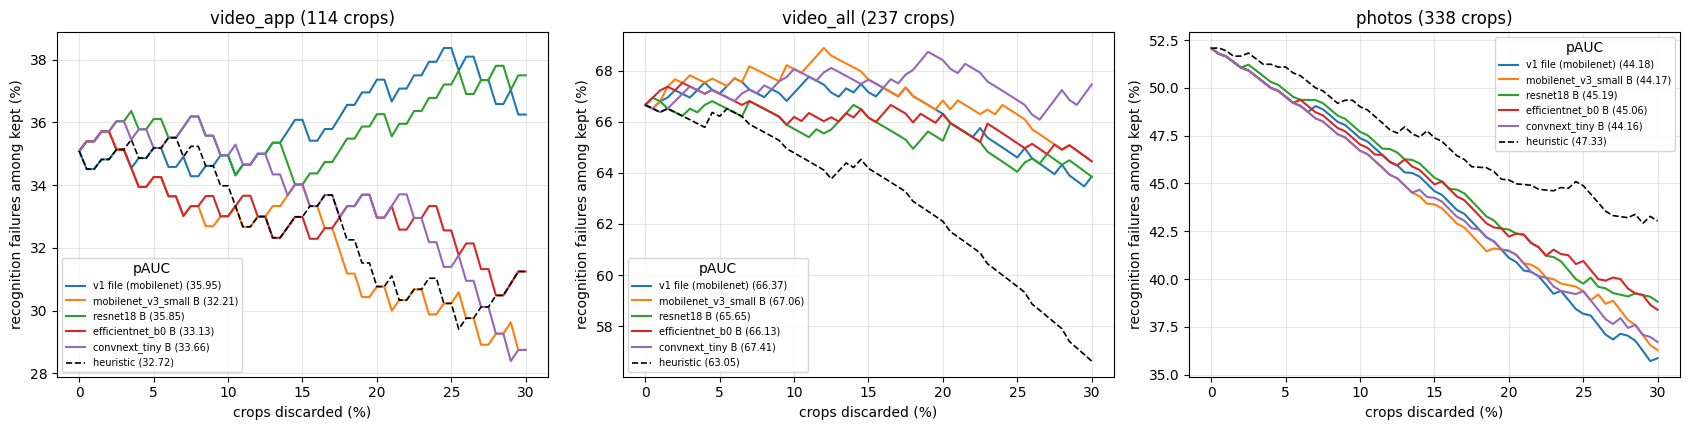

In [7]:
from heuristic import size_term

def edc(score, fail, max_discard=0.30, steps=61):
    order = np.argsort(score)
    xs = np.linspace(0, max_discard, steps)
    ys = np.array([fail[order[int(round(x * len(score))):]].mean() for x in xs])
    return xs, ys, float(getattr(np, "trapezoid", getattr(np, "trapz", None))(ys, xs) / max_discard)

def load_net(arch, sd):
    net = quality.build_model(arch=arch).to(device); net.load_state_dict(sd); net.eval(); return net

v1 = torch.load(REPO / "ml" / "live_face_scan" / "live_face_scan.pt", map_location="cpu", weights_only=True)
methods = {"v1 file (mobilenet)": load_net("mobilenet_v3_small", v1["state_dict"])}
for arch in ARCHS:
    methods[f"{arch} A"] = load_net(arch, trained[arch]["A"])
    methods[f"{arch} B"] = load_net(arch, trained[arch]["B"])
views = {"video_app": te_video_app, "video_all": team_te[team_src[team_te] == "video"], "photos": team_te[team_src[team_te] == "photo"]}
size = np.array([size_term(p) for p in team_px])
res = {"views": {}, "test_people": TEST_PEOPLE, "app_min_face": APP_MIN_FACE,
       "n": {k: int(len(v)) for k, v in views.items()}, "best_stage_A_epoch": {a: trained[a]["best_A_epoch"] for a in ARCHS}}
for view, idx in views.items():
    fail = team_cos[idx] < REC_THR; out = {}
    for name, net in methods.items():
        s = predict(net, team_x[idx])
        out[name] = dict(spearman=spearman(s, team_y[idx]), pAUC=edc(s, fail)[2])
        out[name + " × size"] = dict(spearman=spearman(s * size[idx], team_y[idx]), pAUC=edc(s * size[idx], fail)[2])
    h = np.array([heuristic_score(cv2.resize(team_x[i], (112, 112)), team_px[i]) for i in idx])
    out["heuristic"] = dict(spearman=spearman(h, team_y[idx]), pAUC=edc(h, fail)[2])
    out["size term only"] = dict(spearman=spearman(size[idx], team_y[idx]), pAUC=edc(size[idx] + 1e-6 * np.arange(len(idx)), fail)[2])
    res["views"][view] = dict(failure_rate_at_0=float(fail.mean()), methods=out)
res["kaggle_val_spearman"] = {name: spearman(predict(net, k_images[k_va_s]), k_y[k_va_s]) for name, net in methods.items()}

rows = sorted(res["views"]["video_app"]["methods"].items(), key=lambda kv: kv[1]["pAUC"])
print(f"held-out video faces >= {APP_MIN_FACE} px: n {res['n']['video_app']}, failures with nothing discarded {res['views']['video_app']['failure_rate_at_0']:.1%}")
print(f"{'method':34s} {'video_app pAUC':>14s} {'Spearman':>9s} | {'video_all pAUC':>14s} | {'photos pAUC':>11s} | {'Kaggle Sp':>9s}")
for name, m in rows:
    va, ph = res["views"]["video_all"]["methods"][name], res["views"]["photos"]["methods"][name]
    kg = res["kaggle_val_spearman"].get(name.replace(" × size", ""), float("nan"))
    print(f"{name:34s} {m['pAUC'] * 100:14.2f} {m['spearman']:+9.3f} | {va['pAUC'] * 100:14.2f} | {ph['pAUC'] * 100:11.2f} | {kg:9.3f}")

fig, axes = plt.subplots(1, 3, figsize=(17, 4.4))
for ax, view in zip(axes, views):
    idx = views[view]; fail = team_cos[idx] < REC_THR
    for name in ["v1 file (mobilenet)", *[f"{a} B" for a in ARCHS]]:
        xs, ys, p = edc(predict(methods[name], team_x[idx]), fail)
        ax.plot(xs * 100, ys * 100, label=f"{name} ({p * 100:.2f})")
    h = np.array([heuristic_score(cv2.resize(team_x[i], (112, 112)), team_px[i]) for i in idx])
    xs, ys, p = edc(h, fail); ax.plot(xs * 100, ys * 100, "k--", lw=1.2, label=f"heuristic ({p * 100:.2f})")
    ax.set_title(f"{view} ({len(idx)} crops)"); ax.set_xlabel("crops discarded (%)"); ax.set_ylabel("recognition failures among kept (%)")
    ax.legend(fontsize=7, title="pAUC"); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig(FIG / "backbones_edc.png", dpi=130); plt.show()

## 5. CPU latency (the live scan runs on a laptop CPU)

In [8]:
lat = {}
x1 = torch.rand(1, 3, quality.INPUT_SIZE, quality.INPUT_SIZE)
torch.set_num_threads(2)                             # roughly a laptop's share for this
for arch in ["mobilenet_v3_small", *ARCHS]:
    net = quality.build_model(arch=arch).eval()
    with torch.inference_mode():
        for _ in range(5): net(x1)
        t = time.perf_counter()
        for _ in range(30): net(x1)
    lat[arch] = (time.perf_counter() - t) / 30 * 1000
torch.set_num_threads(max(1, os.cpu_count() or 1))
res["cpu_ms_per_crop"] = lat
print({k: f"{v:.1f} ms" for k, v in lat.items()})

{'mobilenet_v3_small': '8.4 ms', 'resnet18': '20.6 ms', 'efficientnet_b0': '19.7 ms', 'convnext_tiny': '59.8 ms'}


## 6. Apply the selection rule and save the winner

The rule was fixed before the run (top of the notebook): the best `video_app` pAUC among the stage-B models. It
replaces MobileNetV3 only if it beats the MobileNetV3 stage-B model by more than 0.5 pAUC there and is not worse on
`photos`.

In [9]:
vm, pm = res["views"]["video_app"]["methods"], res["views"]["photos"]["methods"]
base = "mobilenet_v3_small B"
best = min((f"{a} B" for a in ARCHS), key=lambda n: vm[n]["pAUC"])
wins = best != base and vm[best]["pAUC"] < vm[base]["pAUC"] - 0.005 and pm[best]["pAUC"] <= pm[base]["pAUC"] + 1e-9
winner = best if wins else base
res["selection"] = dict(best_on_video_app=best, winner=winner, replaces_mobilenet=bool(wins),
                        margin_vs_mobilenet=float(vm[base]["pAUC"] - vm[best]["pAUC"]))
print(f"best on video_app: {best} (pAUC {vm[best]['pAUC'] * 100:.2f} vs mobilenet {vm[base]['pAUC'] * 100:.2f}); "
      f"photos {pm[best]['pAUC'] * 100:.2f} vs {pm[base]['pAUC'] * 100:.2f} -> winner {winner}")

arch = winner.rsplit(" ", 1)[0]
net = methods[winner]
clean_te = team_te[(team_src[team_te] == "photo") & (team_kind[team_te] == "clean")]
thr = float(np.round(np.percentile(predict(net, team_x[clean_te]), 10), 2))
payload = {k: v for k, v in v1.items() if k not in ("state_dict", "history", "architecture")}
payload.update(architecture=f"{arch}_quality", state_dict=trained[arch]["B"], threshold=thr, threshold_domain="webcam",
               threshold_status="06_backbones.ipynb: 10th percentile of the score on held-out clean enrolment photos",
               version=f"06-{arch}", parent="ImageNet" if arch != "resnet18" else "face_recognition v1 backbone",
               history=histories[arch], selection=res["selection"],
               training=dict(v1["training"], backbones=dict(stage_A_epochs=KAGGLE_EPOCHS, best_A_epoch=trained[arch]["best_A_epoch"],
                             stage_B=f"{EPOCHS} x {STEPS_PER_EPOCH} steps, half team / half Kaggle", seed=SEED, device=str(device))))
out = REPO / "ml" / "live_face_scan" / f"face_quality_{arch}.pt"
torch.save(payload, out)
res["histories"] = histories; res["saved"] = out.name; res["saved_threshold"] = thr
(REPO / "ml" / "live_face_scan" / "results_backbones.json").write_text(json.dumps(res, indent=1, ensure_ascii=False), encoding="utf-8")
print(f"saved {out.name} ({out.stat().st_size / 1e6:.1f} MB, threshold {thr}) and results_backbones.json")

best on video_app: mobilenet_v3_small B (pAUC 32.21 vs mobilenet 32.21); photos 44.17 vs 44.17 -> winner mobilenet_v3_small B
saved face_quality_mobilenet_v3_small.pt (4.4 MB, threshold 0.5799999833106995) and results_backbones.json
